# Star Formation History Tables

Build a star formation history table for 600 merger trees between redshifts of $z=4.5-z~14$. I'll record the tellar mass formed in that step $M_*^{\rm new}$, the metallicity $Z$ of the gas it formed from, the stellar mass $M_*$, the dust mass $M_d$ and the intrinsic $L_{1500}$, then the average metallicity of all the stars formed in the tree $\langle Z \rangle$.

Each tree can hold several halos (the progenitors of the galaxy at the base redshift), so I've summed up the quantities over all the halos of that step. 

# Import and Path

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.io import FortranFile
from matplotlib.colors import LinearSegmentedColormap
import smplotlib

findfont: Failed to find font weight normal, now using 500.


In [2]:
root = Path("../").resolve()
path_merger_tree = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/binary_tree_n_progenitors_mh8to14_2_not_mine") / "merger_tree"
path_redshifts = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/redshift_grid_mh8to14.bin")
results = root / "Results_600"
out_dir = Path("data/sfh")
out_dir.mkdir(parents=True, exist_ok=True)
seeds = [12345, 13579, 24680, 32889, 98765]
for seed in seeds:
    print(f"fiducial_seed{seed}", len(list((results / f"fiducial_seed{seed}").glob("merger_tree_out_*"))), "trees")

fiducial_seed12345 600 trees
fiducial_seed13579 600 trees
fiducial_seed24680 600 trees
fiducial_seed32889 600 trees
fiducial_seed98765 600 trees


# Delphi read

In [3]:
timestep_myr = 30.0             #in Myr
return_mass_fraction = 0.14657  #fraction of new_stars given back to the gas

In [4]:
with FortranFile(path_redshifts, "r") as f:
    n_redshifts = f.read_ints(np.int32)[0]
    redshifts = f.read_reals(np.float64)


### Reading delphi files ###
def read_merger_tree(index_tree):
    with FortranFile(f"{path_merger_tree}_{index_tree:05d}", "r") as f:
        n_halos_tree = f.read_ints(np.int32)[0]
        halo_redshift_int = f.read_ints(np.int32)
        halo_mass = f.read_reals(np.float64)       #in Msun
        halo_parent = f.read_ints(np.int32)
        halo_n_progenitors = f.read_ints(np.int32)
    return halo_redshift_int, halo_mass, halo_parent, halo_n_progenitors


def read_merger_tree_out(path_to_output, index_tree):
    # one record per quantity, one entry per halo (delphi.f90:707-720)
    records = []
    with FortranFile(path_to_output / f"merger_tree_out_{index_tree:04d}", "r") as f:
        while True:
            try:
                records.append(f.read_record(np.float64))
            except Exception:
                break
    sfr = records[0]                       #in Msun/yr
    stellar_mass_final = records[1]        #in Msun
    luminosity = np.array(records[2:-9])   #n_wavelength x n_halos_tree
    gas_mass_pre_feedback, gas_mass_final, dust_mass_final, init_metallicity, gas_metallicity = records[-9:-4]
    return sfr, stellar_mass_final, luminosity, gas_mass_pre_feedback, gas_mass_final, dust_mass_final, init_metallicity, gas_metallicity

In [21]:

def sfh_single_tree(output, index_tree):
    halo_redshift_int, halo_mass, halo_parent, halo_n_progenitors = read_merger_tree(index_tree)
    sfr, stellar_mass_final, luminosity, gas_mass_pre_feedback, gas_mass_final, dust_mass_final, init_metallicity, gas_metallicity = read_merger_tree_out(output, index_tree)
    #import pdb; pdb.set_trace()
    
    redshift_values = redshifts[halo_redshift_int - 1]
    halos = pd.DataFrame({"index_tree" : index_tree, "halo_redshift_int": halo_redshift_int, "z":  redshift_values,
                          "new_stars": sfr * timestep_myr * 1e6 ,
                          "metal_mass_new_stars": sfr * timestep_myr  * init_metallicity,
                          "stellar_mass_final": stellar_mass_final,
                          "dust_mass_final": dust_mass_final,
                        "L1500": luminosity[2]})
    sfh = halos.groupby(["index_tree", "halo_redshift_int", "z"], as_index=False).sum()
    sfh["init_metallicity"] = sfh["metal_mass_new_stars"] / sfh["new_stars"].where(sfh["new_stars"] > 0)
    return sfh[["index_tree", "halo_redshift_int", "z", "init_metallicity", "new_stars", "stellar_mass_final", "dust_mass_final", "L1500"]]
    
def add_average_Z(sfh):
    # Weighted by M_new
    Z_avg = {}
    for tid, tree in sfh.groupby("index_tree"):          # tree = the rows of one merger tree
        mass_formed = tree["new_stars"].sum()
        if mass_formed > 0:
            Z_avg[tid] = (tree["new_stars"] * tree["init_metallicity"]).sum() / mass_formed
        else:
            Z_avg[tid] = np.nan                   # this tree formed no stars

    sfh["mean_init_metallicity"] = sfh["index_tree"].map(Z_avg)          # write each tree's <Z> on all of its rows
    return sfh

In [22]:
seed = 32889
tid = 600
run = results / f"fiducial_seed{seed}"
sfh = add_average_Z(sfh_single_tree(run, tid))
sfh

#Halo Mass
#Initial Gass Mass
#Final gas Mass


,index_tree,halo_redshift_int,z,init_metallicity,new_stars,stellar_mass_final,dust_mass_final,L1500,mean_init_metallicity
0,600,1,4.50000,7.238519e-09,3.529655e+11,4.167087e+12,1.818789e+10,1.885677e+44,4.992333e-09
1,600,2,4.58308,7.117257e-09,2.522864e+11,3.865856e+12,1.713441e+10,1.454741e+44,4.992333e-09
2,600,3,4.66934,6.822226e-09,2.961534e+11,3.650547e+12,1.570506e+10,1.609398e+44,4.992333e-09
3,600,4,4.75899,6.766693e-09,2.013098e+11,3.397801e+12,1.484891e+10,1.216178e+44,4.992333e-09
4,600,5,4.85224,6.625994e-09,2.326448e+11,3.225997e+12,1.382903e+10,1.347500e+44,4.992333e-09
5,600,6,4.94933,6.432912e-09,1.607619e+11,3.027451e+12,1.258561e+10,1.110192e+44,4.992333e-09
6,600,7,5.05053,6.194770e-09,4.053397e+11,2.890252e+12,1.167420e+10,2.085517e+44,4.992333e-09
7,600,8,5.15611,5.780380e-09,2.542701e+11,2.544323e+12,1.058276e+10,1.410232e+44,4.992333e-09
8,600,9,5.26639,5.598265e-09,2.347854e+11,2.327321e+12,9.518394e+09,1.295920e+44,4.992333e-09
9,600,10,5.38173,5.313421e-09,1.468788e+11,2.126948e+12,8.626713e+09,9.433012e+43,4.992333e-09


In [25]:
# for every tree, the stellar mass at z = 4.5 is all the mass formed in the tree, minus what was given back to the gas: M_star(z = 4.5) = (1 - R) x sum of M_new, with R = f_yield = 0.14657
def check(sfh, rtol=1e-10):
    mstar = sfh[sfh["halo_redshift_int"] == 1].set_index("index_tree")["stellar_mass_final"]   # DELPHI's M_star at z = 4.5, one per tree
    formed = sfh.groupby("index_tree")["new_stars"].sum()                     # all the mass formed, one per tree
    ok = np.isclose((1 - return_mass_fraction) * formed, mstar, rtol=rtol, atol=0)
    assert ok.all()
check(sfh)


In [26]:
for seed in seeds:
    run = results / f"fiducial_seed{seed}"
    sfh_all = add_average_Z(pd.concat([sfh_single_tree(run, tid) for tid in range(1, 601)], ignore_index=True))
    print(f"seed {seed}: {len(sfh_all)} rows")
    check(sfh_all)                     # stops here with an error if any tree fails
    sfh_all.to_csv(out_dir / f"sfh_seed{seed}_all_trees.csv", index=False)


seed 12345: 20558 rows
seed 13579: 20558 rows
seed 24680: 20558 rows
seed 32889: 20558 rows
seed 98765: 20558 rows


In [28]:
seed = 32889
sfh_all = pd.read_csv(out_dir / f"sfh_seed{seed}_all_trees.csv", index_col=None)
sfh_all[sfh_all["index_tree"] == 600].style.hide(axis="index")    # notebook table without the index

index_tree,halo_redshift_int,z,init_metallicity,new_stars,stellar_mass_final,dust_mass_final,L1500,mean_init_metallicity
600,1,4.500000,0.000000,352965530139.614685,4167087128665.230957,18187890638.046177,188567712012139275080235093381525864259256320.000000,0.000000
600,2,4.583080,0.000000,252286382548.761871,3865855756278.180176,17134405414.062874,145474116580882753631684694554439126295248896.000000,0.000000
600,3,4.669340,0.000000,296153370774.794006,3650546988819.589844,15705063261.361343,160939786941660877623850040032166968888918016.000000,0.000000
600,4,4.758990,0.000000,201309825526.288361,3397800817599.256836,14848908439.781927,121617841591657311892709659792079618733768704.000000,0.000000
600,5,4.852240,0.000000,232644823258.867035,3225996973200.356934,13829032822.510036,134749981065825945139777927862595214853013504.000000,0.000000
600,6,4.949330,0.000000,160761915732.042755,3027450901686.541992,12585605846.979050,111019157768833589403471017636809942547562496.000000,0.000000
600,7,5.050530,0.000000,405339736240.743835,2890251859943.344727,11674203280.525969,208551739788930348205671918946548229079040000.000000,0.000000
600,8,5.156110,0.000000,254270086305.418243,2544322768843.406738,10582763782.286592,141023230088510876404940626697333071048343552.000000,0.000000
600,9,5.266390,0.000000,234785360169.682007,2327321049087.773926,9518393925.983955,129592039526193314621578218850080304471736320.000000,0.000000
600,10,5.381730,0.000000,146878776147.736237,2126948179158.162109,8626713210.185720,94330121907925748427627910877309167074279424.000000,0.000000


# Plots

Panels 1-3: one merger tree (tree_id), at the steps where it formed stars. Panel 4: all 600 merger trees, one point per galaxy at $z = 4.5$.

findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight bold, now using 800.
findfont: Failed to find font weight normal, now using 500.


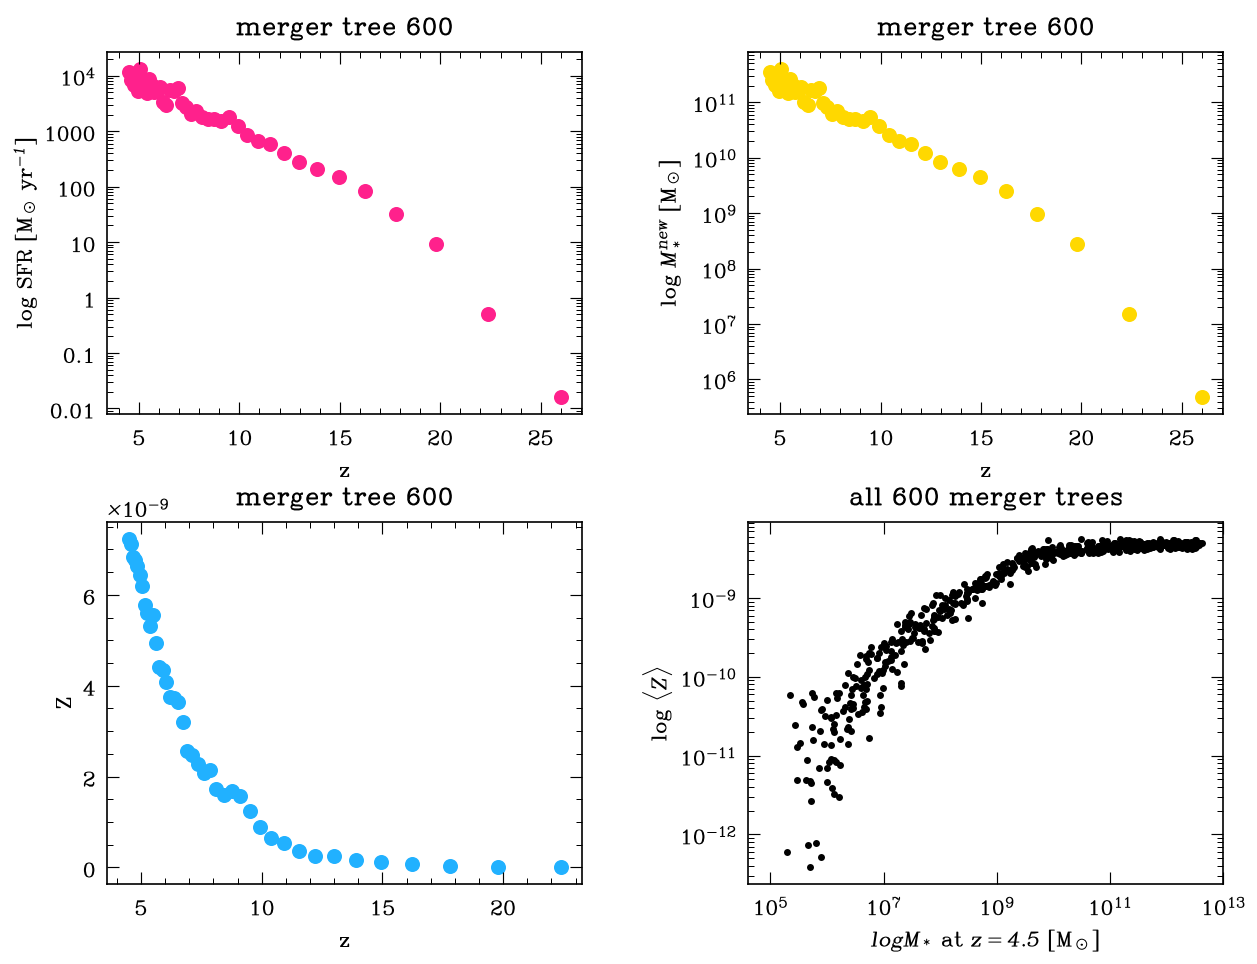

In [30]:
seed = 32889
sfh_all = pd.read_csv(out_dir / f"sfh_seed{seed}_all_trees.csv")
sfh_all["sfr"] = sfh_all["new_stars"] / (timestep_myr * 1e6)   #in Msun/yr
index_tree = 600
tree = sfh_all[(sfh_all["index_tree"] == index_tree) & (sfh_all["new_stars"] > 0)]
tree_metal = tree[tree["init_metallicity"] > 0]   #Z = 0 cannot go on a log axis
galaxies = sfh_all[sfh_all["halo_redshift_int"] == 1]   #one row per tree, z = 4.5

fig, ax = plt.subplots(2, 2, figsize=(12, 9), gridspec_kw={"wspace": 0.35, "hspace": 0.3})
ax[0][0].scatter(tree["z"], tree["sfr"], color="#FF218C")
ax[0][0].set(xlabel="z", ylabel=r"log SFR [M$_\odot$ yr$^{-1}$]", yscale="log", title=f"merger tree {index_tree}")
ax[0][1].scatter(tree["z"], tree["new_stars"], color="#FFD800")
ax[0][1].set(xlabel="z", ylabel=r"log $M_*^{new}$ [M$_\odot$]", yscale="log", title=f"merger tree {index_tree}")
ax[1][0].scatter(tree_metal["z"], tree_metal["init_metallicity"], color="#21B1FF")
ax[1][0].set(xlabel="z", ylabel="Z", title=f"merger tree {index_tree}")
ax[1][1].scatter(galaxies["stellar_mass_final"], galaxies["mean_init_metallicity"], color="black", s=10)
ax[1][1].set(xlabel=r"$log M_*$ at $z = 4.5$ [M$_\odot$]", ylabel=r"log $\langle Z \rangle$", xscale="log", yscale="log", title="all 600 merger trees")
fig.savefig("sfh_panels.png", dpi=200, bbox_inches="tight")
plt.show()

findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.


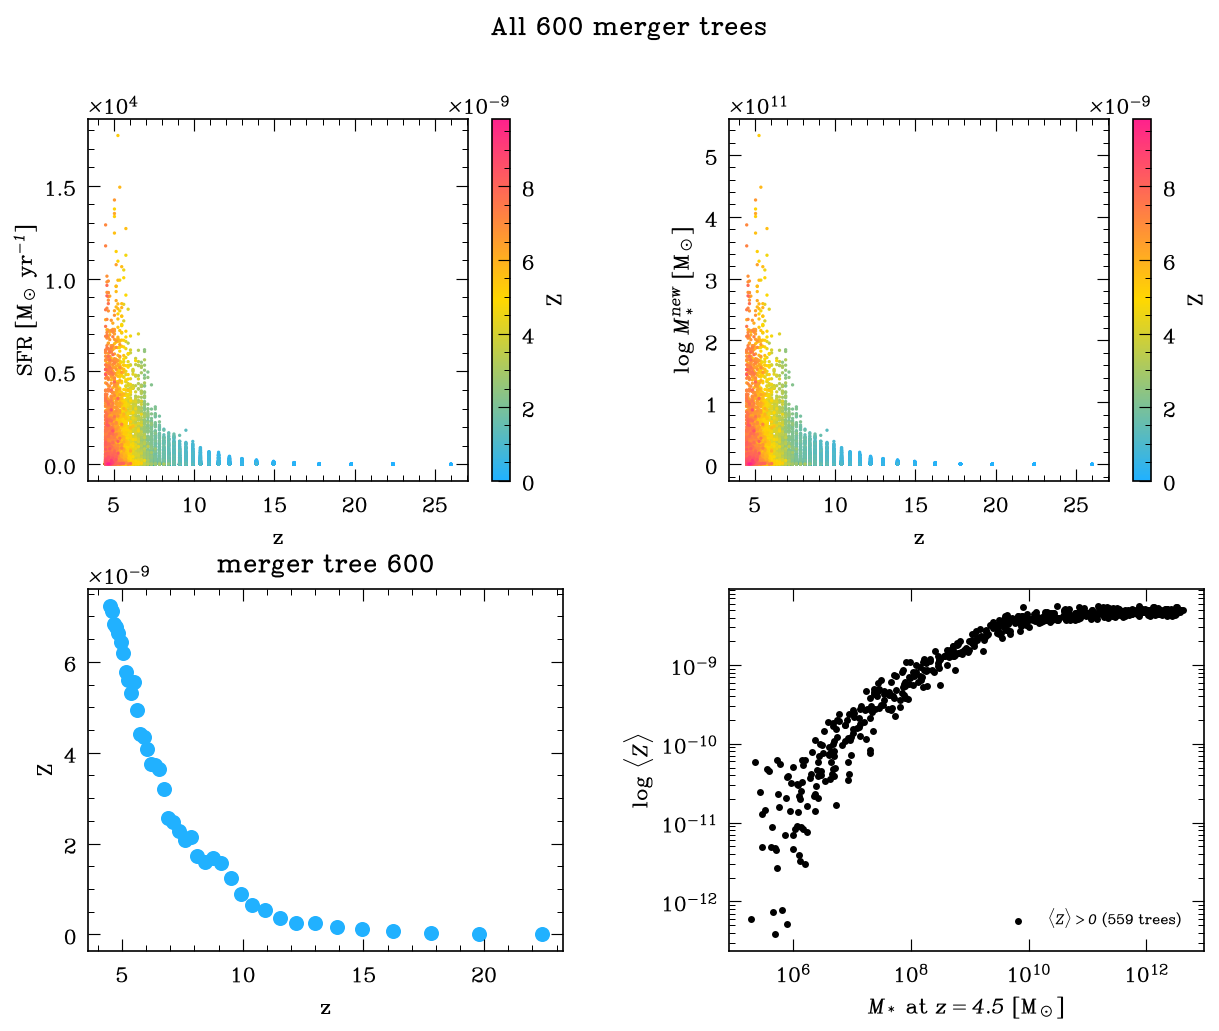

In [31]:
seed = 32889
sfh_all = pd.read_csv(out_dir / f"sfh_seed{seed}_all_trees.csv")
sfh_all["sfr"] = sfh_all["new_stars"] / (timestep_myr * 1e6)   #in Msun/yr
index_tree = 600
tree = sfh_all[(sfh_all["index_tree"] == index_tree) & (sfh_all["new_stars"] > 0)]
tree_metal = tree[tree["init_metallicity"] > 0]   #Z = 0 cannot go on a log axis
galaxies = sfh_all[sfh_all["halo_redshift_int"] == 1]   #one row per tree, z = 4.5
forming = sfh_all[sfh_all["new_stars"] > 0].sort_values("init_metallicity")   #highest Z drawn on top
metal_rich = galaxies[galaxies["mean_init_metallicity"] > 0]
metal_free = galaxies[galaxies["mean_init_metallicity"] == 0]
no_stars = galaxies[galaxies["stellar_mass_final"] == 0]
pansexual = LinearSegmentedColormap.from_list("pansexual", ["#21B1FF", "#FFD800", "#FF218C"])

fig, ax = plt.subplots(2, 2, figsize=(12, 9), gridspec_kw={"wspace": 0.35, "hspace": 0.3})
fig.suptitle("All 600 merger trees")
points = ax[0][0].scatter(forming["z"], forming["sfr"], c=forming["init_metallicity"], cmap=pansexual, s=4, edgecolor="none")
ax[0][0].set(xlabel="z", ylabel=r"SFR [M$_\odot$ yr$^{-1}$]")
fig.colorbar(points, ax=ax[0][0], label="Z")

points = ax[0][1].scatter(forming["z"], forming["new_stars"], c=forming["init_metallicity"], cmap=pansexual, s=4, edgecolors="none")
ax[0][1].set(xlabel="z", ylabel=r"log $M_*^{new}$ [M$_\odot$]")
fig.colorbar(points, ax=ax[0][1], label="Z")

ax[1][0].scatter(tree_metal["z"], tree_metal["init_metallicity"], color="#21B1FF")
ax[1][0].set(xlabel="z", ylabel="Z", title=f"merger tree {index_tree}")

ax[1][1].scatter(metal_rich["stellar_mass_final"], metal_rich["mean_init_metallicity"], color="black", s=10, label=rf"$\langle Z \rangle > 0$ ({len(metal_rich)} trees)")
ax[1][1].set(xlabel=r"$M_*$ at $z = 4.5$ [M$_\odot$]", ylabel=r"log $\langle Z \rangle$", xscale="log", yscale="log")
ax[1][1].legend(loc="lower right", fontsize=10)
fig.savefig("sfh_panels_Z.png", dpi=200, bbox_inches="tight")
plt.show()